# Notebook 2: SQL Analysis (Part C)

In this notebook we load the clean sales data into a **SQLite** database and use SQL to answer the four business questions. We then look at each answer and draw charts.

**How the work is split:**
- **`sql/sales_analytics.sql`** holds all the SQL: the table and the queries.
- **`src/run_analytics.py`** creates the database, loads the data, runs every query and saves each result as a CSV file.
- **This notebook** calls those functions, then shows each query next to its answer and draws the charts. It doesn't repeat any of that work.

In [1]:
# Setup: load the libraries and our analytics script
import sys, sqlite3
from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as mtick

PROJECT_ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(PROJECT_ROOT / "src"))
import run_analytics as ra

CHART_DIR = PROJECT_ROOT / "outputs" / "charts"
CHART_DIR.mkdir(parents=True, exist_ok=True)
pd.set_option("display.float_format", "{:,.2f}".format)

sql = ra.read_sql_blocks()
print("SQL blocks found:", list(sql))

SQL blocks found: ['create_sales_table', 'row_count_check', 'q_a_revenue_per_branch', 'q_b_revenue_per_category', 'q_c_top5_products', 'q_d_average_transaction_value', 'extra_monthly_revenue_by_branch']


## 1. Create the `sales` table
This is the SQL that creates the table. It also sets rules (`CHECK`) so the database refuses bad rows, such as a negative quantity.

In [2]:
# Show the SQL that creates the table
print(sql["create_sales_table"])

-- Step 1: Create the sales table.
-- We delete the old table first, so running the pipeline again starts fresh
-- and never loads the same data twice.
DROP TABLE IF EXISTS sales;

CREATE TABLE sales (
    transaction_id   TEXT    PRIMARY KEY,                 -- each sale appears only once
    transaction_date TEXT    NOT NULL,                    -- stored as YYYY-MM-DD
    branch           TEXT    NOT NULL,
    product          TEXT    NOT NULL,
    category         TEXT    NOT NULL,
    quantity         INTEGER NOT NULL CHECK (quantity > 0),
    unit_price       INTEGER NOT NULL CHECK (unit_price > 0),   -- in Uganda shillings
    total_amount     INTEGER NOT NULL CHECK (total_amount = quantity * unit_price)
);
-- The CHECK rules are a second safety net: the database will refuse any row
-- with a zero or negative quantity or price, or a wrong total.

-- Indexes make searching and grouping by these columns faster.
CREATE INDEX idx_sales_branch   ON sales (branch);
CREATE INDEX idx_sal

## 2. Load `cleaned_sales.csv` into the table
`build_database()` creates the database file `warehouse/sales.db`, makes the table, and then adds every row from `cloud_storage_bucket/sales/2026/cleaned_sales.csv`. Finally it checks that the number of rows in the table matches the file.

In [3]:
# Create the database, load the data, and count the rows (should be 102)
conn = ra.build_database()
pd.read_sql_query(sql["row_count_check"], conn)

2026-10-15 13:00:53,697 | INFO    | LOAD     | 102 rows inserted into sales from cloud_storage_bucket\sales\2026\cleaned_sales.csv


,rows_loaded
0,102


In [4]:
# Look at the first 5 rows in the table
pd.read_sql_query("SELECT * FROM sales LIMIT 5", conn)

,transaction_id,transaction_date,branch,product,category,quantity,unit_price,total_amount
0,T001,2026-01-03,Kampala,Laptop,Electronics,2,2500000,5000000
1,T002,2026-01-03,Mbarara,Printer,Electronics,3,650000,1950000
2,T003,2026-01-04,Jinja,Office Chair,Furniture,5,350000,1750000
3,T004,2026-01-05,Kampala,Desk,Furniture,2,480000,960000
4,T005,2026-01-06,Mbarara,Keyboard,Accessories,10,75000,750000


## 3. Run all the queries
`run_queries()` runs every query in the SQL file once and saves each result as a CSV file in `outputs/query_results/`. It gives back all the results, so below we just look at them.

In [5]:
# Run every query once and save each result as a CSV file
results = ra.run_queries(conn)
for f in sorted((PROJECT_ROOT / "outputs" / "query_results").glob("*.csv")):
    print(f.relative_to(PROJECT_ROOT))

2026-10-15 13:01:16,632 | INFO    | QUERY    | row_count_check                     -> 1 row(s) -> row_count_check.csv
2026-10-15 13:01:16,637 | INFO    | QUERY    | q_a_revenue_per_branch              -> 3 row(s) -> q_a_revenue_per_branch.csv
2026-10-15 13:01:16,643 | INFO    | QUERY    | q_b_revenue_per_category            -> 3 row(s) -> q_b_revenue_per_category.csv
2026-10-15 13:01:16,649 | INFO    | QUERY    | q_c_top5_products                   -> 5 row(s) -> q_c_top5_products.csv
2026-10-15 13:01:16,655 | INFO    | QUERY    | q_d_average_transaction_value       -> 1 row(s) -> q_d_average_transaction_value.csv
2026-10-15 13:01:16,659 | INFO    | QUERY    | extra_monthly_revenue_by_branch     -> 12 row(s) -> extra_monthly_revenue_by_branch.csv


outputs\query_results\extra_monthly_revenue_by_branch.csv
outputs\query_results\q_a_revenue_per_branch.csv
outputs\query_results\q_b_revenue_per_category.csv
outputs\query_results\q_c_top5_products.csv
outputs\query_results\q_d_average_transaction_value.csv
outputs\query_results\row_count_check.csv


## 4. Business questions
For each question, we print the SQL and then show its answer.

### a) What is the total revenue for each branch?

In [6]:
# The SQL for question a, then its answer
print(sql["q_a_revenue_per_branch"])
q_a = results["q_a_revenue_per_branch"]
q_a

-- Question a) What is the total revenue for each branch?
-- We also show each branch's share of total revenue as a percentage.
SELECT
    branch,
    COUNT(*)                                   AS transactions,
    SUM(quantity)                              AS units_sold,
    SUM(total_amount)                          AS total_revenue,
    ROUND(100.0 * SUM(total_amount)
          / (SELECT SUM(total_amount) FROM sales), 2) AS revenue_share_pct
FROM sales
GROUP BY branch
ORDER BY total_revenue DESC;


,branch,transactions,units_sold,total_revenue,revenue_share_pct
0,Kampala,34,180,61395000,35.65
1,Mbarara,34,185,59410000,34.49
2,Jinja,34,197,51435000,29.86


### b) What is the total revenue for each product category?

In [7]:
# The SQL for question b, then its answer
print(sql["q_b_revenue_per_category"])
q_b = results["q_b_revenue_per_category"]
q_b

-- Question b) What is the total revenue for each product category?
SELECT
    category,
    COUNT(*)                                   AS transactions,
    SUM(quantity)                              AS units_sold,
    SUM(total_amount)                          AS total_revenue,
    ROUND(100.0 * SUM(total_amount)
          / (SELECT SUM(total_amount) FROM sales), 2) AS revenue_share_pct
FROM sales
GROUP BY category
ORDER BY total_revenue DESC;


,category,transactions,units_sold,total_revenue,revenue_share_pct
0,Electronics,45,96,109850000,63.78
1,Furniture,29,106,42170000,24.48
2,Accessories,28,360,20220000,11.74


### c) Which 5 products brought in the most money?

In [8]:
# The SQL for question c, then its answer
print(sql["q_c_top5_products"])
q_c = results["q_c_top5_products"]
q_c

-- Question c) Which 5 products brought in the most money?
SELECT
    product,
    category,
    SUM(quantity)       AS units_sold,
    SUM(total_amount)   AS total_sales
FROM sales
GROUP BY product, category
ORDER BY total_sales DESC
LIMIT 5;


,product,category,units_sold,total_sales
0,Laptop,Electronics,21,52500000
1,Monitor,Electronics,43,36550000
2,Office Chair,Furniture,67,23450000
3,Printer,Electronics,32,20800000
4,Desk,Furniture,39,18720000


### d) How much is an average transaction worth?

In [9]:
# The SQL for question d, then its answer
print(sql["q_d_average_transaction_value"])
q_d = results["q_d_average_transaction_value"]
q_d

-- Question d) How much is an average transaction worth?
-- We also show the smallest and largest transactions for context.
SELECT
    COUNT(*)                     AS transactions,
    SUM(total_amount)            AS total_revenue,
    ROUND(AVG(total_amount), 2)  AS average_transaction_value,
    MIN(total_amount)            AS smallest_transaction,
    MAX(total_amount)            AS largest_transaction
FROM sales;


,transactions,total_revenue,average_transaction_value,smallest_transaction,largest_transaction
0,102,172240000,"1,688,627.45",525000,5000000


### Extra: how did each branch's revenue change month by month?
April only has data up to the 14th, so its numbers are lower.

In [10]:
# Show the monthly totals as a table: one row per month, one column per branch
q_e = results["extra_monthly_revenue_by_branch"]
q_e.pivot(index="month", columns="branch", values="total_revenue")

branch,Jinja,Kampala,Mbarara
month,,,
2026-01,14335000,19750000,17315000
2026-02,14830000,14805000,17235000
2026-03,16395000,14800000,18610000
2026-04,5875000,12040000,6250000


## 5. Charts
Revenue is shown in **millions of Uganda shillings (UGX)**. The bar charts use one colour, since each one compares a single measure. The monthly chart gives each branch its own colour.

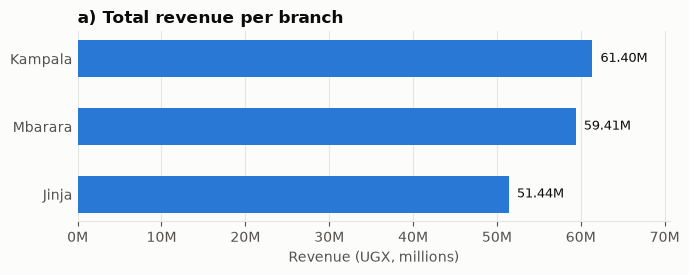

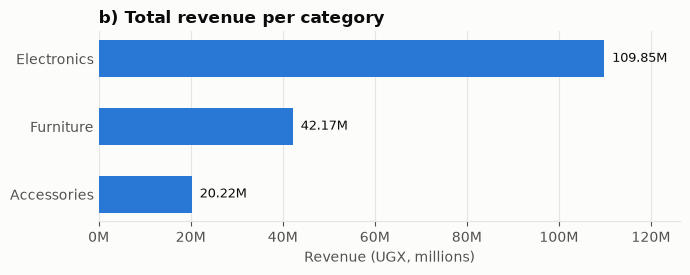

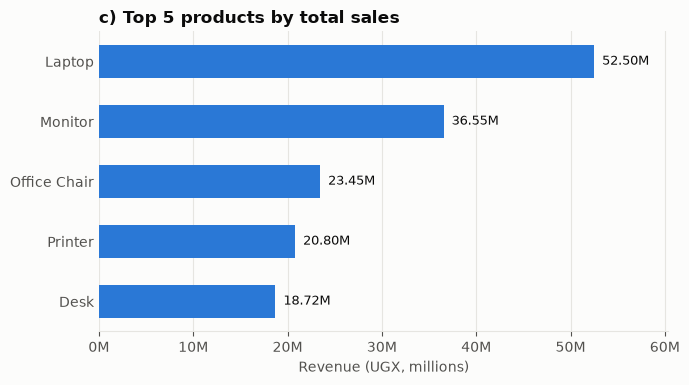

In [11]:
# Chart colours and style, then bar charts for questions a, b and c
BLUE = "#2a78d6"
BRANCH_COLORS = {"Kampala": "#2a78d6", "Mbarara": "#eb6834", "Jinja": "#1baf7a"}
INK, INK2, GRID = "#0b0b0b", "#52514e", "#e6e5e1"

plt.rcParams.update({
    "figure.facecolor": "#fcfcfb", "axes.facecolor": "#fcfcfb",
    "axes.edgecolor": GRID, "axes.labelcolor": INK2, "xtick.color": INK2, "ytick.color": INK2,
    "axes.spines.top": False, "axes.spines.right": False, "axes.spines.left": False,
    "font.size": 10, "axes.titlesize": 12, "axes.titleweight": "bold", "axes.titlecolor": INK,
})

def hbar(df, label_col, value_col, title, fname):
    d = df.sort_values(value_col)
    fig, ax = plt.subplots(figsize=(7, 0.55 * len(d) + 1.2))
    vals = d[value_col] / 1e6
    ax.barh(d[label_col], vals, color=BLUE, height=0.55)
    ax.xaxis.set_major_formatter(mtick.StrMethodFormatter("{x:,.0f}M"))
    ax.grid(axis="x", color=GRID, linewidth=0.8); ax.set_axisbelow(True)
    ax.tick_params(axis="y", length=0)
    for y, v in enumerate(vals):
        ax.text(v, y, f"  {v:,.2f}M", va="center", color=INK, fontsize=9)
    ax.set_xlim(0, vals.max() * 1.15)
    ax.set_title(title, loc="left"); ax.set_xlabel("Revenue (UGX, millions)")
    fig.tight_layout(); fig.savefig(CHART_DIR / fname, dpi=150); plt.show()

hbar(q_a, "branch",   "total_revenue", "a) Total revenue per branch",          "q_a_revenue_per_branch.png")
hbar(q_b, "category", "total_revenue", "b) Total revenue per category",        "q_b_revenue_per_category.png")
hbar(q_c, "product",  "total_sales",   "c) Top 5 products by total sales",     "q_c_top5_products.png")

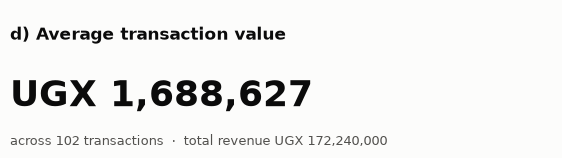

In [12]:
# d) The average is a single number, so we show it as a big headline number instead of a chart
avg = q_d.loc[0, "average_transaction_value"]
fig, ax = plt.subplots(figsize=(7, 1.8)); ax.axis("off")
ax.text(0, 0.78, "d) Average transaction value", fontsize=12, fontweight="bold", color=INK, transform=ax.transAxes)
ax.text(0, 0.30, f"UGX {avg:,.0f}", fontsize=26, fontweight="bold", color=INK, transform=ax.transAxes)
ax.text(0, 0.02, f"across {q_d.loc[0,'transactions']} transactions  ·  total revenue UGX {q_d.loc[0,'total_revenue']:,.0f}",
        fontsize=9, color=INK2, transform=ax.transAxes)
fig.savefig(CHART_DIR / "q_d_average_transaction_value.png", dpi=150, bbox_inches="tight"); plt.show()

2026-10-15 13:01:47,505 | INFO    | Using categorical units to plot a list of strings that are all parsable as floats or dates. If these strings should be plotted as numbers, cast to the appropriate data type before plotting.
2026-10-15 13:01:47,508 | INFO    | Using categorical units to plot a list of strings that are all parsable as floats or dates. If these strings should be plotted as numbers, cast to the appropriate data type before plotting.
2026-10-15 13:01:47,511 | INFO    | Using categorical units to plot a list of strings that are all parsable as floats or dates. If these strings should be plotted as numbers, cast to the appropriate data type before plotting.
2026-10-15 13:01:47,514 | INFO    | Using categorical units to plot a list of strings that are all parsable as floats or dates. If these strings should be plotted as numbers, cast to the appropriate data type before plotting.
2026-10-15 13:01:47,518 | INFO    | Using categorical units to plot a list of strings that are a

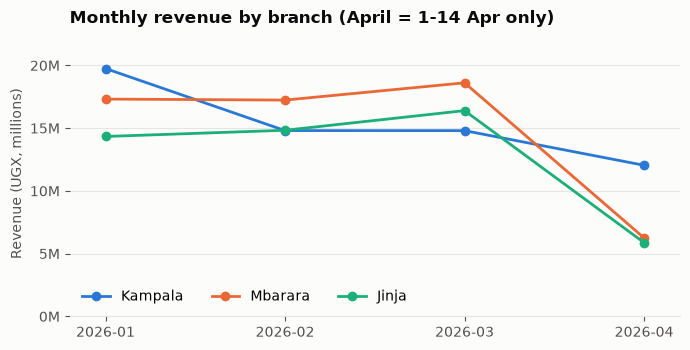

In [13]:
# Extra chart: monthly revenue for each branch (April only covers 1-14 April)
pv = q_e.pivot(index="month", columns="branch", values="total_revenue") / 1e6
fig, ax = plt.subplots(figsize=(7, 3.6))
for b in ["Kampala", "Mbarara", "Jinja"]:
    ax.plot(pv.index, pv[b], color=BRANCH_COLORS[b], linewidth=2, marker="o", markersize=6, label=b)
ax.yaxis.set_major_formatter(mtick.StrMethodFormatter("{x:,.0f}M"))
ax.grid(axis="y", color=GRID, linewidth=0.8); ax.set_axisbelow(True)
ax.set_ylim(0, pv.values.max() * 1.15); ax.set_xlim(-0.2, len(pv) - 0.8)
ax.set_title("Monthly revenue by branch (April = 1-14 Apr only)", loc="left")
ax.set_ylabel("Revenue (UGX, millions)"); ax.legend(frameon=False, loc="lower left", ncol=3)
fig.tight_layout(); fig.savefig(CHART_DIR / "extra_monthly_revenue_by_branch.png", dpi=150); plt.show()

## 6. Picture of the query results
This puts all four answers into one image, for the assignment's *screenshot or export of query outputs* requirement.

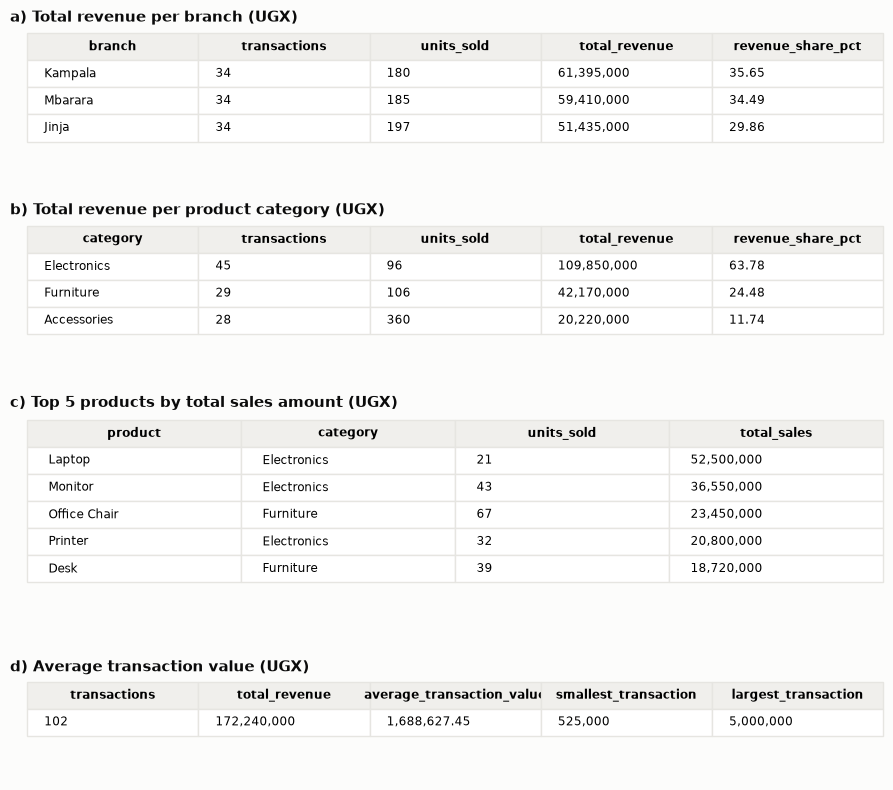

In [14]:
# Draw each result as a table and save them together as one image
def table_panel(ax, df, title):
    ax.axis("off"); ax.set_title(title, loc="left", fontsize=11)
    fmt = df.copy()
    for c in fmt.columns:
        if pd.api.types.is_numeric_dtype(fmt[c]):
            fmt[c] = fmt[c].map(lambda v: f"{v:,.2f}" if isinstance(v, float) and v % 1 else f"{v:,.0f}")
    t = ax.table(cellText=fmt.values, colLabels=fmt.columns, loc="upper left", cellLoc="left")
    t.auto_set_font_size(False); t.set_fontsize(8.5); t.scale(1, 1.35)
    for (r, _), cell in t.get_celld().items():
        cell.set_edgecolor(GRID)
        if r == 0: cell.set_text_props(weight="bold"); cell.set_facecolor("#f0efec")

fig, axes = plt.subplots(4, 1, figsize=(9, 8), gridspec_kw={"height_ratios": [1.1, 1.1, 1.6, 0.7]})
table_panel(axes[0], q_a, "a) Total revenue per branch (UGX)")
table_panel(axes[1], q_b, "b) Total revenue per product category (UGX)")
table_panel(axes[2], q_c, "c) Top 5 products by total sales amount (UGX)")
table_panel(axes[3], q_d, "d) Average transaction value (UGX)")
fig.tight_layout(); fig.savefig(CHART_DIR / "query_outputs_screenshot.png", dpi=150); plt.show()

In [15]:
# Close the database connection
conn.close()

## 7. What we found
* **Kampala** made the most money (about 35.7% of revenue), even though it sold fewer items than Jinja. This is because it sold more expensive electronics.
* **Electronics** brought in about 64% of all revenue from only 96 items. **Accessories** sold the most items (360) but brought in only about 12%.
* **Laptops** alone brought in UGX 52.5 million, about 30% of all revenue.
* An **average transaction** is worth about **UGX 1.69 million**. The smallest was UGX 525,000 and the largest UGX 5 million.